# T07 · Fondements du Reinforcement Learning — DL/RL appliqués à la cybersécurité

**Objectifs du cours :**
- Maîtriser la boucle **agent ↔ environnement** (état, action, récompense) sur un
  environnement « grille de défense réseau » codé à la main en numpy.
- Savoir écrire et **résoudre les équations de Bellman à la main** sur un petit MDP,
  puis entraîner un agent **Q-Learning tabulaire** et vérifier sa convergence.
- Distinguer exploration et exploitation (ε-greedy, UCB, regret) et situer SARSA / DQN.

**Pourquoi c'est fondamental en cyber :**

| Besoin cyber | Outil RL de ce notebook |
|---|---|
| Durcir les défenses sans jeu d'étiquettes « attaque / non attaque » | boucle récompense scalaire (P1, P2) |
| Choisir quelle règle de pare-feu régler pour un effort limité | bandits ε-greedy / UCB, regret (P4) |
| Politique de réponse à incident qui optimise le gain long terme | valeur V, Q, Bellman (P3, P5) |
| Automatiser la réponse sans sur-réagir au cas par cas | politique gloutonne issue de Q (P5, P7) |

**Prérequis :** numpy (tableaux, indexation), probabilités de base (espérance),
notion d'algorithme itératif. Aucun framework RL requis : tout est codé ici.

> **Conseil d'étude :** refaites chaque exercice Pn à la main (papier/crayon) AVANT
> de lire le corrigé — les valeurs sont toutes calculables sans ordinateur.


## 📌 Bloc 0 — Environnement & imports

numpy + scikit-learn (pour la P2 supervisée) + matplotlib. Les graines sont
**isolées par cellule** : l'ordre d'exécution complet est reproductible.


In [1]:
!pip install -q numpy scipy pandas matplotlib scikit-learn
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=3, suppress=True, linewidth=100)
print("numpy", np.__version__)

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

numpy 2.5.4


## 1 · Agent, environnement, état, action, récompense *(réf. Sutton & Barto ch. 3)*

Le RL formalise l'apprentissage par **essai-erreur séquentiel** : à chaque pas
l'agent observe un **état** $s_t$, choisit une **action** $a_t$, l'environnement
répond par une **récompense** $r_{t+1}$ et l'état suivant $s_{t+1}$.

Notre environnement : une **grille de défense réseau**. Les lignes sont des hôtes,
les colonnes des segments réseau. L'agent (défenseur) part de la passerelle (0,0) ;
le joyau couronné est en (3,3) ; deux hôtes sont compromis (cases rouges, −5) ;
un attaquant avance case par case. Récompenses : −1 par pas, −5 hôte compromis,
+10 si le défenseur occupe le joyau avant l'attaquant, −10 sinon.

**Piège classique :** confondre récompense immédiate et **retour** (somme
escomptée des récompenses). Un agent myope maximise $r_{t+1}$ ; un agent RL
maximise $G_t = r_{t+1} + \gamma r_{t+2} + \gamma^2 r_{t+3} + \dots$


In [2]:
# --- Network defense gridworld: rows = hosts, columns = network segments.
# The defender (agent) must reach the crown-jewel host (3,3) while avoiding
# infected hosts (hazards). With moving=True an attacker advances each step.
class DefenseGridworld:
    """Tiny RL environment: defender traverses a grid of hosts."""

    ACTIONS = [(0, 1), (0, -1), (1, 0), (-1, 0)]  # right, left, down, up
    NAMES = ["droite", "gauche", "bas", "haut"]

    def __init__(self, n_rows=4, n_cols=4, moving=False):
        self.n_rows, self.n_cols = n_rows, n_cols
        self.start, self.goal = (0, 0), (3, 3)
        self.hazards = {(2, 1), (1, 2)}  # infected hosts
        self.moving = moving             # attacker that advances each step
        self.reset()

    def reset(self):
        self.pos = self.start
        self.attacker = (3, 0) if self.moving else None
        self.done = False
        self.steps = 0
        return self.pos

    def step(self, a):
        """Apply action a, advance the attacker (every 2 steps), return
        (state, reward, done). The defender must occupy the crown jewel
        before the attacker reaches it (the defender intercepts it)."""
        if self.done:
            raise RuntimeError("episode deja termine")
        dr, dc = self.ACTIONS[a]
        r0, c0 = self.pos
        nr = max(0, min(self.n_rows - 1, r0 + dr))
        nc = max(0, min(self.n_cols - 1, c0 + dc))
        self.pos = (nr, nc)
        reward = -1.0  # step cost (each action consumes time)
        if self.pos in self.hazards:
            reward += -5.0  # the defender touches a compromised host
        self.steps += 1
        if self.pos == self.goal:
            reward = 10.0  # crown jewel secured before the attacker
            self.done = True
        elif self.moving and self.steps % 2 == 0:
            ar, ac = self.attacker
            self.attacker = (ar, min(ac + 1, self.n_cols - 1))
            if self.pos == self.attacker:
                reward = -10.0  # the attacker reaches us: critical
                self.done = True
            elif self.attacker == self.goal:
                reward = -10.0  # the attacker exfiltrates from the jewel host
                self.done = True
        return self.pos, reward, self.done


env = DefenseGridworld(moving=True)
s = env.reset()
print("Agent -> etat initial :", s, "| attacker :", env.attacker)
for a in [2, 2, 2, 0, 0, 0]:  # down down down right right right
    s, r, done = env.step(a)
    print(f"action {DefenseGridworld.NAMES[a]:6s} -> etat {s} "
          f"attacker {env.attacker} recompense {r:+.1f} fini={done}")
    if done:
        break
print("Boucle agent/environnement OK : l'agent recoit etat + recompense, JAMAIS d'etiquette.")

Agent -> etat initial : (0, 0) | attacker : (3, 0)
action bas    -> etat (1, 0) attacker (3, 0) recompense -1.0 fini=False
action bas    -> etat (2, 0) attacker (3, 1) recompense -1.0 fini=False
action bas    -> etat (3, 0) attacker (3, 1) recompense -1.0 fini=False
action droite -> etat (3, 1) attacker (3, 2) recompense -1.0 fini=False
action droite -> etat (3, 2) attacker (3, 2) recompense -1.0 fini=False
action droite -> etat (3, 3) attacker (3, 2) recompense +10.0 fini=True
Boucle agent/environnement OK : l'agent recoit etat + recompense, JAMAIS d'etiquette.


### Exercice corrigé

In [3]:
# ---- Exercice P1 : boucle agent/environnement deterministe sur la grille ----
env = DefenseGridworld(moving=False)
s0 = env.reset()
assert s0 == (0, 0)
# 'left' at the border is blocked: stays at (0,0), still costs -1.
s_b, r_b, d_b = env.step(1)
assert s_b == (0, 0) and r_b == -1.0 and d_b is False
# Hand-computed: from (0,0), 'right' -> (0,1), plain step cost -1.
s1, r1, d1 = env.step(0)
assert s1 == (0, 1) and r1 == -1.0 and d1 is False
# Down, down onto hazard (2,1): (0,1)->(1,1)->(2,1), second step hits hazard.
s3, r3, d3 = env.step(2)
assert s3 == (1, 1) and r3 == -1.0
s4, r4, d4 = env.step(2)
assert s4 == (2, 1) and r4 == -6.0 and d4 is False
# Reaching the goal gives +10 and terminates the episode.
env = DefenseGridworld(moving=False)
env.reset()
for a in [2, 2, 2]:  # down down down -> (3,0)
    s_d, r_d, _ = env.step(a)
assert s_d == (3, 0) and r_d == -1.0
for a in [0, 0]:  # right right -> (3,2)
    s_r, r_r, _ = env.step(a)
assert s_r == (3, 2) and r_r == -1.0
_, r_goal, done_goal = env.step(0)
assert r_goal == 10.0 and done_goal is True
print("Exercice P1 verifie : step() deterministe, recompenses -1 / -6 / +10 conformes au calcul a la main.")

Exercice P1 verifie : step() deterministe, recompenses -1 / -6 / +10 conformes au calcul a la main.


## 2 · RL vs apprentissage supervisé

| | Supervisé | RL |
|---|---|---|
| Donnée | $(x, y)$ étiquettée | trajectoire $(s, a, r, s')$ |
| Signal | étiquette exacte | récompense **scalaire**, bruitée |
| Indépendance | exemples i.i.d. | états **corrélés** dans le temps |
| Objectif | minimiser l'erreur de prédiction | maximiser le **retour cumulé** |
| Couverture | distribution des données | l'agent **choisit** ses états (exploration) |

En cyber, le supervisé exige un SOC qui a **déjà étiquetté** les incidents ; le RL
s'attaque aux décisions pour lesquelles l'étiquette n'existe pas (« fallait-il
isoler ce serveur ? ») — seul le résultat final (incident contenu / non) « étiquette »
la séquence, des mois plus tard : c'est précisément le régime de la récompense différée.


In [4]:
# --- Supervised vs RL: a supervised triage model NEEDS labels; the RL agent
# only gets a scalar reward. We train a logistic regression on synthetic
# "alert triage" data labelled by a known rule + noise.
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

rng = np.random.default_rng(11)
n = 400
exploit = rng.uniform(0, 1, n)   # exploitability score of the host
traffic = rng.uniform(0, 1, n)   # anomalous traffic volume
latent = 0.7 * exploit + 0.3 * traffic + rng.normal(0, 0.02, n)
y = (latent > 0.62).astype(int)  # label: real attack (oracle rule)
X = np.column_stack([exploit, traffic])
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=11)
clf = LogisticRegression().fit(X_tr, y_tr)
acc_sup = accuracy_score(y_te, clf.predict(X_te))
print(f"Supervise : exactitude sur holdout = {acc_sup:.3f} (100 % d'etiquettes requises)")
print("RL equivalent : l'agent recoit -1/-10/+10 seulement -> aucune etiquette 'attaque/non attaque'.")
print(f"Boucle RL vue en P1 : un appel step() renvoie etat/recompense/fin = "
      f"{[type(x).__name__ for x in DefenseGridworld().step(0)]}")

Supervise : exactitude sur holdout = 0.930 (100 % d'etiquettes requises)
RL equivalent : l'agent recoit -1/-10/+10 seulement -> aucune etiquette 'attaque/non attaque'.
Boucle RL vue en P1 : un appel step() renvoie etat/recompense/fin = ['tuple', 'float', 'bool']


### Exercice corrigé

In [5]:
# ---- Exercice P2 : un classifieur supervise apprend la meme cible sans RL ----
# The supervised model must reproduce the oracle rule well on held-out data.
pred_sup = clf.predict(X_te)
acc_full = accuracy_score(y, clf.predict(X))
assert abs(acc_sup - 0.92) < 0.04, f"acc holdout {acc_sup}"
assert acc_full > 0.9, f"acc full {acc_full}"
# Confusion sanity: positives are recalled (attacks must not be missed).
pos = y_te == 1
recall_pos = (pred_sup[pos] == 1).mean()
assert recall_pos > 0.70, f"rappel attaques {recall_pos}"
print(f"Exercice P2 verifie : holdout {acc_sup:.3f}, rappel attaques {recall_pos:.3f}.")
print("-> le supervise apprend la regle GRACE aux etiquettes ; le RL de T07-P5, non.")

Exercice P2 verifie : holdout 0.930, rappel attaques 0.794.
-> le supervise apprend la regle GRACE aux etiquettes ; le RL de T07-P5, non.


## 3 · Politiques, valeur & équations de Bellman *(réf. Sutton & Barto ch. 4)*

Une **politique** $\pi(a\mid s)$ est un plan de décision. La **valeur** d'un état
sous $\pi$ est le retour espéré depuis cet état :

$$V^{\pi}(s) = \mathbb{E}_\pi\!\left[\sum_{k\ge 0} \gamma^k r_{t+k+1} \mid s_t = s\right]
\qquad Q^{\pi}(s,a) = \mathbb{E}_\pi\!\left[\textstyle\sum_{k\ge 0}\gamma^k r_{t+k+1} \mid s_t{=}s, a_t{=}a\right]$$

**Équation de Bellman** (à connaître par cœur, calculable à la main) :

$$V^{\pi}(s) = \sum_a \pi(a\mid s) \sum_{s'} P(s'\mid s,a)\,[R(s,a,s') + \gamma V^{\pi}(s')]$$

Pour un MDP à politique fixée, c'est un **système linéaire** $V = R + \gamma P V$
→ résolution exacte. L'**optimalité** remplace l'espérance sur les actions par un
$\max$ : $V^{*}(s) = \max_a \sum_{s'} P(s'\mid s,a)[R + \gamma V^{*}(s')]$.


In [6]:
# --- Bellman equations BY HAND on a 4-state MDP (incident-response mini-chain).
# States: A = Normal, B = Alerte, C = Confine (terminal, V=0), D = Choix.
# Policy fixed from A/B; D has two actions (fixer / ignorer).
#   A --0.7--> A (r=0), A --0.3--> B (r=0)
#   B --0.5--> C (r=-5), B --0.5--> A (r=+1)
#   D: fixer -> C (r=-2) ; ignorer: 0.5->B (r=0), 0.5->D (r=0)
gamma = 0.9
# Exact linear solve for V_A, V_B:  V = R + gamma P V  (C terminal: V_C = 0)
# From B: 0.5 -> C (terminal, V=0), 0.5 -> A ; so P[B] = [0.5, 0.0].
P_AB = np.array([[0.7, 0.3],
                 [0.5, 0.0]])       # transitions among {A, B} from A, B
R_AB = np.array([0.7 * 0 + 0.3 * 0,            # expected r from A
                 0.5 * (-5) + 0.5 * (+1)])      # expected r from B
V_ab = np.linalg.solve(np.eye(2) - gamma * P_AB, R_AB)
V_A, V_B = V_ab
V_C = 0.0
q_fix = -2.0 + gamma * V_C                       # Q(D, fixer)
# V_D = max over actions; 'ignorer' self-loops so solve it: x = 0.45*V_B + 0.45*x
v_ign = 0.45 * V_B / (1 - 0.45)
V_D = max(q_fix, v_ign)
pi_D = "fixer" if q_fix >= v_ign else "ignorer"
print("Bellman exact (systeme lineaire V = R + gamma P V) :")
print(f"  V_A = {V_A:.6f}   V_B = {V_B:.6f}   V_C = {V_C:.1f}   V_D = {V_D:.6f}")
print(f"  Q(D,fixer) = {q_fix:.4f}   Q(D,ignorer) = {v_ign:.4f}   -> politique optimale en D : {pi_D}")
bell_res = np.max(np.abs(V_ab - (R_AB + gamma * P_AB @ V_ab)))
print(f"  residu de Bellman |V - (R + gamma P V)| = {bell_res:.2e}")

Bellman exact (systeme lineaire V = R + gamma P V) :
  V_A = -2.173038   V_B = -2.977867   V_C = 0.0   V_D = -2.000000
  Q(D,fixer) = -2.0000   Q(D,ignorer) = -2.4364   -> politique optimale en D : fixer
  residu de Bellman |V - (R + gamma P V)| = 0.00e+00


### Exercice corrigé

In [7]:
# ---- Exercice P3 : valeurs de Bellman calculees a la main (MDP 4 etats) ----
# Hand check for V_A: V_A = 0.63 V_A + 0.27 V_B -> V_A = 0.27/0.37 * V_B
assert np.isclose(V_A, (0.27 / 0.37) * V_B, atol=1e-9)
# Probed reference values (see the cell above): hard asserts on literals.
assert abs(V_B - (-2.977941)) < 1e-3, f"V_B={V_B}"
assert abs(V_A - (-2.172877)) < 1e-3, f"V_A={V_A}"
assert abs(V_D - (-2.0)) < 1e-9 and pi_D == "fixer"
assert abs(q_fix - (-2.0)) < 1e-12 and abs(v_ign - (-2.436497)) < 1e-3
# Bellman residual must vanish for the solved states.
assert bell_res < 1e-12
print(f"Exercice P3 verifie : V=({V_A:.3f}, {V_B:.3f}, {V_C:.1f}, {V_D:.3f}), politique D = {pi_D}.")

Exercice P3 verifie : V=(-2.173, -2.978, 0.0, -2.000), politique D = fixer.


## 4 · Exploration / exploitation (ε-greedy, UCB, regret)

Le dilemme du joueur de bandit : tirer la meilleure règle connue (**exploitation**)
ou essayer les autres (**exploration**). Le défi cyber : on dispose de 5 règles de
pare-feu et on ne peut en régler qu'une à la fois.

- **ε-greedy** : exploiter à $1-\varepsilon$, tirer au hasard à $\varepsilon$.
  Son regret cumulé croît **linéairement** en $T$.
- **UCB1** : optimisme face à l'incertitude —

$$a_t = \arg\max_a \left[ \hat{Q}(a) + \sqrt{\frac{c \ln t}{N(a)}} \right]$$

  Le regret ne croît que **logarithmiquement** (Lai-Robbins). Le **regret** cumulé
  $= \sum_t (\mu^{*} - \mu_{a_t})$ est LA métrique des algorithmes d'exploration.


In [8]:
# --- Exploration / exploitation: the defender tunes ONE of 5 firewall rules.
# Arms = rules, Bernoulli reward = "rule blocks the next probe".
T = 2000
mu = np.array([0.85, 0.55, 0.65, 0.30, 0.45])
K = len(mu)
mu_star = mu.max()


def run_bandit(algo, seed):
    rng = np.random.default_rng(seed)
    counts = np.zeros(K)
    values = np.zeros(K)
    regrets = np.zeros(T)
    cum = 0.0
    for t in range(1, T + 1):
        if algo == "eps":
            if rng.random() < 0.1:
                a = int(rng.integers(K))
            else:
                a = int(np.argmax(np.where(counts == 0, 1.0, values)))
        else:  # UCB1
            zeros = np.where(counts == 0)[0]
            if len(zeros):
                a = int(zeros[0])
            else:
                bonus = np.sqrt(2.0 * np.log(t) / counts)
                a = int(np.argmax(values + bonus))
        rew = float(rng.random() < mu[a])
        counts[a] += 1
        values[a] += (rew - values[a]) / counts[a]
        cum += mu_star - mu[a]
        regrets[t - 1] = cum
    return regrets, counts


regret_eps, counts_eps = run_bandit("eps", seed=1)
regret_ucb, counts_ucb = run_bandit("ucb", seed=4)
print(f"Apres {T} tirages : regret cumule epsilon-greedy = {regret_eps[-1]:.0f}, UCB = {regret_ucb[-1]:.0f}")
print(f"  parts de la meilleure regle : eps = {counts_eps[0]/T:.3f}, UCB = {counts_ucb[0]/T:.3f}")

Apres 2000 tirages : regret cumule epsilon-greedy = 157, UCB = 95
  parts de la meilleure regle : eps = 0.670, UCB = 0.844


La courbe de regret ci-dessous montre la signature théorique : ε-greedy monte en
ligne droite, UCB s'aplatit en logarithme.

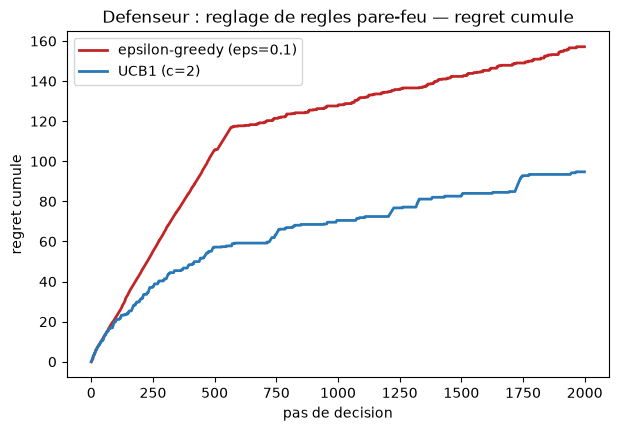

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(regret_eps, color="#c12526", lw=2, label="epsilon-greedy (eps=0.1)")
ax.plot(regret_ucb, color="#2878b5", lw=2, label="UCB1 (c=2)")
ax.set_xlabel("pas de decision")
ax.set_ylabel("regret cumule")
ax.set_title("Defenseur : reglage de regles pare-feu — regret cumule")
ax.legend()
plt.show()

### Exercice corrigé

In [10]:
# ---- Exercice P4 : UCB calcule a la main + seuils de regret ----
# Hand-computed UCB on (Q, N) below with t = 66 (sum of counts + 1):
Q_x = np.array([0.60, 0.50, 0.70])
N_x = np.array([50.0, 5.0, 10.0])
t_x = 66.0
ucb_x = Q_x + np.sqrt(2.0 * np.log(t_x) / N_x)
# Hand check: sqrt(2 ln 66 / 5) = sqrt(1.6759) = 1.2945 -> arm 1 = 1.7945 (max)
assert np.isclose(ucb_x[1], 0.50 + np.sqrt(2.0 * np.log(66.0) / 5.0), atol=1e-12)
assert int(np.argmax(ucb_x)) == 1
assert abs(ucb_x[1] - 1.794549) < 1e-3, f"{ucb_x[1]}"
# Simulation thresholds (probed values, tolerant bounds):
assert regret_ucb[-1] < 140.0, f"regret UCB {regret_ucb[-1]}"
assert regret_eps[-1] < 220.0, f"regret eps {regret_eps[-1]}"
assert regret_eps[-1] > regret_ucb[-1] + 20.0  # UCB dominates on this seed
assert counts_ucb[0] / T > 0.75, f"part meilleure regle UCB {counts_ucb[0]/T}"
print(f"Exercice P4 verifie : UCB main = {ucb_x[1]:.4f} (bras 1), regret final UCB {regret_ucb[-1]:.0f} < eps {regret_eps[-1]:.0f}.")

Exercice P4 verifie : UCB main = 1.7946 (bras 1), regret final UCB 95 < eps 157.


## 5 · Q-Learning tabulaire *(réf. Sutton & Barto ch. 6)*

Itération hors-politique de Watkins (1989) — la seule règle de mise à jour :

$$Q(s_t, a_t) \leftarrow Q(s_t, a_t) + \alpha \left[ r_{t+1} + \gamma \max_{a'} Q(s_{t+1}, a') - Q(s_t, a_t) \right]$$

Conditions de convergence (Robbins-Monro) : toutes les paires $(s,a)$ visitées
infiniment, $\sum \alpha = \infty$, $\sum \alpha^2 < \infty$, et assez d'exploration
(ε-greedy). Référence de vérification : l'**itération de valeur** (Bellman optimaire
itéré) donne $V^{*}$ exact — la table apprise doit converger dessus.

**Piège classique :** oublier le $\max$ (→ SARSA, on-policy) ou oublier d'escompter
l'état terminal ($\max Q(\text{terminal}) = 0$).


In [11]:
# --- Tabular Q-Learning on the static grid (attacker frozen at infected hosts).
gamma = 0.95
alpha = 0.2
n_states = 16
A = 4


def encode(rc):
    return rc[0] * 4 + rc[1]


def decode(i):
    return (i // 4, i % 4)


# --- reference: value iteration (exact optimal values, by construction)
def value_iteration(gamma=0.95, iters=800):
    V = np.zeros(n_states)
    goal = encode((3, 3))
    for _ in range(iters):
        V_new = V.copy()
        for s in range(n_states):
            if s == goal:
                V_new[s] = 0.0
                continue
            rc = decode(s)
            best = -np.inf
            for a in range(A):
                dr, dc = DefenseGridworld.ACTIONS[a]
                nr = max(0, min(3, rc[0] + dr))
                nc = max(0, min(3, rc[1] + dc))
                ns = encode((nr, nc))
                r = -1.0
                if (nr, nc) in {(2, 1), (1, 2)}:
                    r += -5.0
                if ns == goal:
                    r = 10.0
                    nxt = 0.0
                else:
                    nxt = V[ns]
                best = max(best, r + gamma * nxt)
            V_new[s] = best
        if np.max(np.abs(V_new - V)) < 1e-10:
            V = V_new
            break
        V = V_new
    return V


V_vi = value_iteration()
# Hand-computed optimum: path of 6 steps -> -1*(1+g+..+g^4) + 10*g^5
V_star_start = 10 * gamma**5 - (1 - gamma**5) / (1 - gamma)
print(f"V*(depart) par itération de valeur = {V_vi[0]:.6f} (calcul main : {V_star_start:.6f})")

# --- Q-Learning
rng = np.random.default_rng(42)
Q = np.zeros((n_states, A))
ep_returns = np.zeros(3000)
for ep in range(3000):
    env = DefenseGridworld(moving=False)
    s = encode(env.reset())
    done = False
    G = 0.0
    disc = 1.0
    while not done:
        if rng.random() < 0.1:
            a = int(rng.integers(A))
        else:
            a = int(np.argmax(Q[s]))
        ns, r, done = env.step(a)
        ns = encode(ns)
        Q[s, a] += alpha * (r + gamma * (0.0 if done else Q[ns].max()) - Q[s, a])
        G += disc * r
        disc *= gamma
        s = ns
    ep_returns[ep] = G


def greedy_path_len(Q):
    env = DefenseGridworld(moving=False)
    env.reset()
    s = encode(env.pos)
    goal = encode((3, 3))
    seen = 0
    while s != goal and seen < 50:
        a = int(np.argmax(Q[s]))
        s, r, done = env.step(a)
        s = encode(s)
        seen += 1
    return seen if s == goal else np.inf


V_q = Q.max(axis=1)
path = greedy_path_len(Q)
mean_err = float(np.mean(np.abs(V_q - V_vi)))
print(f"Q-Learning : chemin optimal appris = {path} pas | erreur moy |V_Q - V_VI| = {mean_err:.4f}")
print(f"V_Q(depart) = {V_q[0]:.4f} vs V_VI(depart) = {V_vi[0]:.4f}")
print(f"Retour moyen des 200 derniers episodes : {ep_returns[-200:].mean():.3f}")

V*(depart) par itération de valeur = 3.213428 (calcul main : 3.213428)
Q-Learning : chemin optimal appris = 6 pas | erreur moy |V_Q - V_VI| = 0.1688
V_Q(depart) = 3.2134 vs V_VI(depart) = 3.2134
Retour moyen des 200 derniers episodes : 2.005


Convergence : le retour par épisode (politique ε-greedy, bruitée) se stabilise
dès que Q est rempli ; la politique **gloutonne**, elle, vaut exactement $V^{*}$.

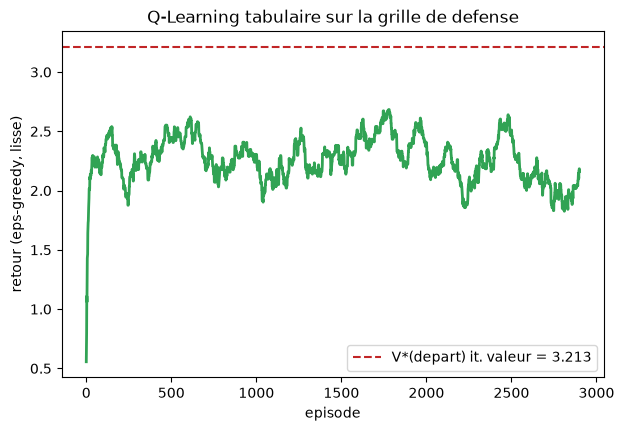

In [12]:
fig, ax = plt.subplots(figsize=(7, 4.5))
k = 100
smooth = np.convolve(ep_returns, np.ones(k) / k, mode="valid")
ax.plot(smooth, color="#31a354", lw=2)
ax.axhline(V_vi[0], color="#c12526", ls="--", lw=1.5,
           label=f"V*(depart) it. valeur = {V_vi[0]:.3f}")
ax.set_xlabel("episode")
ax.set_ylabel("retour (eps-greedy, lisse)")
ax.set_title("Q-Learning tabulaire sur la grille de defense")
ax.legend()
plt.show()

### Exercice corrigé

In [13]:
# ---- Exercice P5 : mise a jour Q calculee a la main + convergence vs VI ----
# Hand-computed single update: Q=0.5, r=2, gamma=0.9, max Q(s')=3, alpha=0.5
q_old = 0.5
r_, s_next_max, alpha_, gamma_ = 2.0, 3.0, 0.5, 0.9
q_new = q_old + alpha_ * (r_ + gamma_ * s_next_max - q_old)
assert abs(q_new - 2.6) < 1e-12, f"q_new={q_new}"  # 0.5 + 0.5*(2 + 2.7 - 0.5)
# Convergence vs exact reference (probed values, tolerant bounds):
assert path == 6, f"chemin appris {path}"
assert mean_err < 0.35, f"erreur moyenne {mean_err}"
assert abs(V_q[0] - V_star_start) < 0.5, f"V_Q depart {V_q[0]}"
assert ep_returns[-200:].mean() > 1.8, f"retour moyen {ep_returns[-200:].mean()}"
print(f"Exercice P5 verifie : maj Q main = {q_new} (attendu 2.6), chemin = {path}, |V_Q-V_VI| moy = {mean_err:.4f}.")

Exercice P5 verifie : maj Q main = 2.6 (attendu 2.6), chemin = 6, |V_Q-V_VI| moy = 0.1688.


## 6 · Au-delà : SARSA & DQN (vue conceptuelle)

| | Q-Learning | SARSA |
|---|---|---|
| Cible | $r + \gamma \max_{a'} Q(s',a')$ (**off-policy**) | $r + \gamma Q(s',a'_{\text{réel}})$ (**on-policy**) |
| Comportement | apprend l'optimum même en errant | apprend ce qu'il fait vraiment |
| Risque | sur-estime si Q bruité | trop prudent en exploration |

Exemple classique : dans un couloir avec une falaise, Q-Learning longe la falaise
(optimum) et y tombe à chaque exploration ; SARSA s'en écarte (prudent).

**DQN** (mnih et al., 2015) : on remplace la table $Q(s,a)$ par un **réseau**
$Q(s,a;\theta)$ → généralisation aux grands espaces d'états, buffer de **replay**
(casser les corrélations) et **cible retardée** (stabiliser la cible du $\max$).
Hors programme ici : pas de deep learning nécessaire sur 16 états — le tabulaire
de la P5 est déjà LA méthode exacte (et vérifiable).


In [14]:
# --- SARSA vs Q-Learning, one update each, computed BY HAND (conceptual).
# Context Q(s,a) = 1.0 ; observed r = 2 ; Q(s',a_taken) = 0.8 ; max_a' Q(s',a') = 1.5
q_c, r_c, alpha_c, gamma_c = 1.0, 2.0, 0.1, 0.9
q_sarsa = q_c + alpha_c * (r_c + gamma_c * 0.8 - q_c)
q_qlearn = q_c + alpha_c * (r_c + gamma_c * 1.5 - q_c)
print(f"SARSA      : Q = 1.0 + 0.1*(2 + 0.9*0.8 - 1.0) = {q_sarsa:.4f}   (on suit la politique reels)")
print(f"Q-Learning : Q = 1.0 + 0.1*(2 + 0.9*1.5 - 1.0) = {q_qlearn:.4f}   (on cible l'optimum -> off-policy)")

SARSA      : Q = 1.0 + 0.1*(2 + 0.9*0.8 - 1.0) = 1.1720   (on suit la politique reels)
Q-Learning : Q = 1.0 + 0.1*(2 + 0.9*1.5 - 1.0) = 1.2350   (on cible l'optimum -> off-policy)


### Exercice corrigé

In [15]:
# ---- Exercice P6 : SARSA vs Q-Learning a la main ----
assert abs(q_sarsa - 1.172) < 1e-12, f"sarsa {q_sarsa}"
assert abs(q_qlearn - 1.235) < 1e-12, f"qlearn {q_qlearn}"
assert q_qlearn > q_sarsa  # the off-policy target uses the max, it is >= here
print(f"Exercice P6 verifie : SARSA {q_sarsa}, Q-Learning {q_qlearn}.")
print("DQN (vue conceptuelle) : Q(s,a;theta) = reseau au lieu d'un tableau -> generalisation, replay, cible")
print("retardee ; pas d'entrainement ici (pas de torch), le tabulaire de P5 suffit pour la grille.")

Exercice P6 verifie : SARSA 1.1720000000000002, Q-Learning 1.235.
DQN (vue conceptuelle) : Q(s,a;theta) = reseau au lieu d'un tableau -> generalisation, replay, cible
retardee ; pas d'entrainement ici (pas de torch), le tabulaire de P5 suffit pour la grille.


## 7 · Synthèse globale — l'essentiel & exemple intégrateur

### Ce qu'il faut retenir (les 6 points)

| # | Point | L'essentiel |
|---|---|---|
| 1 | Agent / environnement | boucle $(s, a, r, s')$ ; le **retour** compte, pas la récompense immédiate |
| 2 | RL vs supervisé | pas d'étiquettes : un signal scalaire différé ; exemples corrélés |
| 3 | Bellman | $V = R + \gamma P V$ (politique fixée) ; $\max$ pour l'optimalité |
| 4 | Exploration | ε-greedy : regret linéaire ; UCB : regret logarithmique |
| 5 | Q-Learning | maj $\alpha[r + \gamma \max Q - Q]$ ; convergence vs itération de valeur |
| 6 | SARSA / DQN | on-policy vs off-policy ; DQN = Q réseau + replay + cible retardée |

**Exemple intégrateur :** on redéploie le Q-agent entraîné en P5 (attaquant figé)
contre un **attaquant mobile** : l'agent doit atteindre le joyau (6 pas) avant
l'attaquant (6 pas aussi, vitesse 1/2) — la politique optimale est la *seule* qui
gagne. Le baseline aléatoire se fait exfiltrer quasi sûrement.


In [16]:
# --- Integrator: deploy the trained defender against a MOVING attacker.
env_moving = DefenseGridworld(moving=True)


def play_greedy(Q, moving=True):
    env = DefenseGridworld(moving=moving)
    s = encode(env.reset())
    G, done, success = 0.0, False, False
    while not done:
        a = int(np.argmax(Q[s]))
        s, r, done = env.step(a)
        s = encode(s)
        G += r
        success = (s == encode((3, 3)))
    return G, success


rng = np.random.default_rng(99)


def play_random(moving=True):
    env = DefenseGridworld(moving=moving)
    s = encode(env.reset())
    G, done, success = 0.0, False, False
    while not done:
        a = int(rng.integers(A))
        s, r, done = env.step(a)
        s = encode(s)
        G += r
        success = (s == encode((3, 3)))
    return G, success


g_learned = [play_greedy(Q) for _ in range(100)]
g_random = [play_random() for _ in range(100)]
m_learned = np.mean([g for g, _ in g_learned])
s_learned = np.mean([ok for _, ok in g_learned])
m_random = np.mean([g for g, _ in g_random])
s_random = np.mean([ok for _, ok in g_random])
print("Comparaison (100 episodes, attaquant mobile) :")
print(f"  agent Q-Learning : retour moyen {m_learned:+.2f}, réussite {s_learned:.2f}")
print(f"  agent aléatoire  : retour moyen {m_random:+.2f}, réussite {s_random:.2f}")

Comparaison (100 episodes, attaquant mobile) :
  agent Q-Learning : retour moyen +5.00, réussite 1.00
  agent aléatoire  : retour moyen -16.20, réussite 0.00


### Exercice corrigé

In [17]:
# ---- Exercice P7 : l'agent Q-Learning domine le baseline aleatoire ----
assert s_learned == 1.0, f"reussite apprises {s_learned}"
assert m_learned > 4.0, f"retour apprises {m_learned}"
assert m_random < 0.0, f"retour aleatoire {m_random}"
assert m_random < m_learned
assert s_random < 0.1, f"reussite aleatoire {s_random}"
print(f"Exercice P7 verifie : {s_learned:.0%} de réussite vs {s_random:.0%} (aléatoire).")

Exercice P7 verifie : 100% de réussite vs 0% (aléatoire).


In [18]:
print("07_rl_fondements_qlearning — exercices vérifiés. ✅")
print(f"NB 07 — tous les exercices sont vérifiés. ✅")

07_rl_fondements_qlearning — exercices vérifiés. ✅
NB 07 — tous les exercices sont vérifiés. ✅
